# Customer Purchase Prediction | Data Preparation and Neural Network Classification

**Scope:** Portfolio presentation of an educational practical-exam project. The supplied files represent three separate tasks rather than one continuous dataset lineage: raw data cleaning (500 records), feature preparation (500 different records), and neural-network modelling (800 labelled training records plus 200 unlabelled prediction records). We do **not** claim that Task 1 outputs directly generate Task 3 inputs.

**Objective:** Prepare customer-session data, demonstrate numerical scaling and categorical encoding, and train/evaluate a PyTorch binary purchase classifier.

**Important limitations:** Educational data, not a production model. Purchase class balance must be checked. `basket_value` may introduce target leakage if it is recorded after purchase; feature timing is unknown. Unlabelled validation predictions cannot provide ground-truth evaluation metrics.


# Task 1

The marketing team has collected customer session data in `raw_customer_data.csv`, but it contains missing values and inconsistencies that need to be addressed.
Create a cleaned version of the dataframe:

- Start with the data in the file `raw_customer_data.csv`
- Your output should be a DataFrame named `clean_data`
- All column names and values should match the table below.
</br>

| Column Name | Criteria |
|------------|----------|
| customer_id | Integer. Unique identifier for each customer. No missing values. |
| time_spent | Float. Minutes spent on website per session. Missing values should be replaced with median. |
| pages_viewed | Integer. Number of pages viewed in session. Missing values should be replaced with mean. |
| basket_value | Float. Value of items in basket. Missing values should be replaced with 0. |
| device_type | String. One of: Mobile, Desktop, Tablet. Missing values should be replaced with "Unknown". |
| customer_type | String. One of: New, Returning. Missing values should be replaced with "New". |
| purchase | Binary. Whether customer made a purchase (1) or not (0). Target variable. |

In [20]:
# Write your answer to Task 1 here
import pandas as pd
data = pd.read_csv("data/raw_customer_data.csv")

data = data.replace(["-", "missing","","N/A", "NA"], pd.NA)
data["time_spent"] = data["time_spent"].fillna(data["time_spent"].median())
data["pages_viewed"] =data ["pages_viewed"].fillna(data["pages_viewed"].mean()).round()
data["basket_value"] =data ["basket_value"].fillna(0)
data["device_type"] =data ["device_type"].fillna("Unknown")
data["customer_type"] =data ["customer_type"].fillna("New")

data["customer_id"] =data ["customer_id"].astype(int)
data["time_spent"] =data ["time_spent"].astype(float)
data["pages_viewed"] =data ["pages_viewed"].astype(int)
data["basket_value"] =data ["basket_value"].astype(float)
data["device_type"] =data ["device_type"].astype(str)
data["customer_type"] =data ["customer_type"].astype(str)
data["purchase"] =data ["purchase"].astype(int)

clean_data = data[ [ "customer_id" ,"time_spent", "pages_viewed", "basket_value", "device_type", "customer_type", "purchase" ] ]





# Task 2
The pre-cleaned dataset `model_data.csv` needs to be prepared for our neural network.
Create the model features:

- Start with the data in the file `model_data.csv`
- Scale numerical features (`time_spent`, `pages_viewed`, `basket_value`) to 0-1 range
- Apply one-hot encoding to the categorical features (`device_type`, `customer_type`)
    - The column names should have the following format: variable_name_category_name (e.g., `device_type_Desktop`)
- Your output should be a DataFrame named `model_feature_set`, with all column names from `model_data.csv` except for the columns where one-hot encoding was applied.


In [21]:
# Write your answer to Task 2 here
import pandas as pd
from sklearn.preprocessing import MinMaxScaler

model_data = pd.read_csv("data/model_data.csv")

numerical_features = [ "time_spent", "pages_viewed", "basket_value"]

scaler = MinMaxScaler()
model_data[numerical_features] = scaler.fit_transform(model_data[numerical_features])

model_feature_set = pd.get_dummies(model_data, columns = ["device_type", "customer_type"], dtype = int)

# Task 3

Now that all preparatory work has been done, create and train a neural network that would allow the company to predict purchases.

- Using PyTorch, create a network with:
   - At least one hidden layer with 8 units
   - ReLU activation for hidden layer
   - Sigmoid activation for the output layer
- Using the prepared features in `input_model_features.csv`, train the model to predict purchases.
- Use the validation dataset `validation_features.csv` to predict new values based on the trained model.
- Your model should be named `purchase_model` and your output should be a DataFrame named `validation_predictions` with columns `customer_id` and `purchase`. The `purchase` column must be your predicted values.


In [16]:
# Write your answer to Task 3 here
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim

train_data = pd.read_csv("data/input_model_features.csv")
validation_data = pd.read_csv("data/validation_features.csv")

X_train = train_data.drop(columns = ["customer_id", "purchase"])
y_train = train_data["purchase"]

X_validation = validation_data.drop(columns = ["customer_id"])

X_train_tensor = torch.tensor(X_train.values , dtype = torch.float32)
y_train_tensor = torch.tensor(y_train.values , dtype = torch.float32).reshape(-1, 1)


X_validation_tensor= torch.tensor(X_validation.values , dtype = torch.float32)

class PurchaseNetwork(nn.Module):

    def __init__(self, input_size):
        super().__init__()

        self.hidden = nn.Linear(input_size, 8)
        self.output = nn.Linear(8,1)
    def forward(self , x):
        x=torch.relu(self.hidden(x))
        x= torch.sigmoid(self.output(x))
        return x
purchase_model = PurchaseNetwork(X_train.shape[1])

criterion = nn.BCELoss()

optimizer = optim.Adam(purchase_model.parameters(), lr = 0.001)


for epoch in range (100):
    predictions = purchase_model(X_train_tensor)
    loss = criterion(predictions, y_train_tensor)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

purchase_model.eval()

with torch.no_grad():
    probabilities = purchase_model(X_validation_tensor)
predicted_purchase = (probabilities >=0.5).int().numpy().flatten()

validation_predictions = pd.DataFrame({"customer_id":validation_data["customer_id"], "purchase": predicted_purchase})

## Additional portfolio evaluation (new work)

The original practical exam trained on all 800 labelled observations and predicted 200 unlabelled records. Here we add a **separate reproducible held-out evaluation** to assess the model before fitting it on all labelled data for the original prediction task. We compare against a majority-class baseline, use stratification, and report class-sensitive metrics. No scores are claimed until the cells are executed.


In [17]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay, classification_report

torch.manual_seed(42)
np.random.seed(42)

X = train_data.drop(columns=["customer_id", "purchase"])
y = train_data["purchase"].astype(int)
print("Class distribution (label counts):")
print(y.value_counts().sort_index())
print("Purchase rate:", round(y.mean(), 3))

X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
X_tr_t = torch.tensor(X_tr.to_numpy(), dtype=torch.float32)
X_te_t = torch.tensor(X_te.to_numpy(), dtype=torch.float32)
y_tr_t = torch.tensor(y_tr.to_numpy(), dtype=torch.float32).reshape(-1, 1)

def train_network(x, labels, epochs=100):
    torch.manual_seed(42)
    net = PurchaseNetwork(x.shape[1])
    loss_fn = nn.BCELoss()
    opt = optim.Adam(net.parameters(), lr=0.001)
    losses = []
    for _ in range(epochs):
        net.train()
        opt.zero_grad()
        prob = net(x)
        loss = loss_fn(prob, labels)
        loss.backward()
        opt.step()
        losses.append(float(loss.item()))
    net.eval()
    return net, losses

holdout_model, losses = train_network(X_tr_t, y_tr_t)
with torch.no_grad():
    test_probs = holdout_model(X_te_t).numpy().ravel()
model_preds = (test_probs >= 0.5).astype(int)

baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_tr, y_tr)
baseline_preds = baseline.predict(X_te)

def metrics(name, predictions):
    return {"Model": name, "Accuracy": accuracy_score(y_te, predictions),
            "Precision": precision_score(y_te, predictions, zero_division=0),
            "Recall": recall_score(y_te, predictions, zero_division=0),
            "F1": f1_score(y_te, predictions, zero_division=0)}

results = pd.DataFrame([metrics("Majority baseline", baseline_preds), metrics("PyTorch neural network", model_preds)])
print(results.round(3).to_string(index=False))
print("\nNeural-network classification report:\n", classification_report(y_te, model_preds, zero_division=0))


Class distribution (label counts):
purchase
0    168
1    632
Name: count, dtype: int64
Purchase rate: 0.79
                 Model  Accuracy  Precision  Recall    F1
     Majority baseline     0.788      0.788   1.000 0.881
PyTorch neural network     0.775      0.788   0.976 0.872

Neural-network classification report:
               precision    recall  f1-score   support

           0       0.25      0.03      0.05        34
           1       0.79      0.98      0.87       126

    accuracy                           0.78       160
   macro avg       0.52      0.50      0.46       160
weighted avg       0.67      0.78      0.70       160



## Evaluation visuals

The loss curve shows training optimization, **not** generalization. The confusion matrix reveals the types of mistakes made on the held-out set. Neither chart alone establishes deployment readiness.


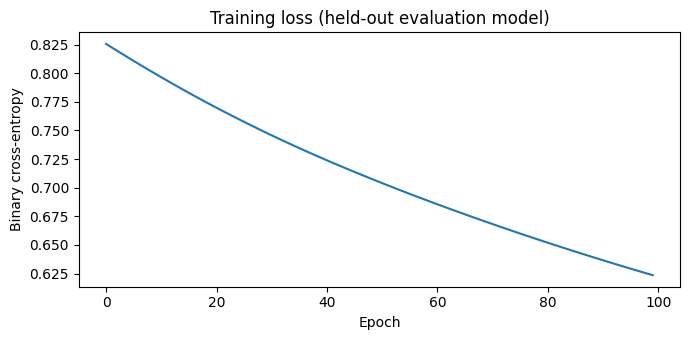

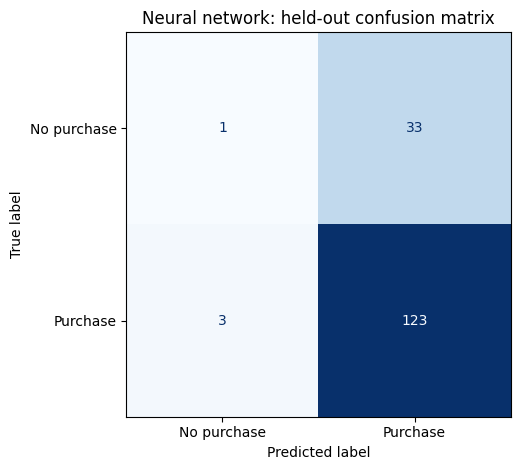

In [18]:
plt.figure(figsize=(7, 3.5))
plt.plot(losses)
plt.xlabel("Epoch")
plt.ylabel("Binary cross-entropy")
plt.title("Training loss (held-out evaluation model)")
plt.tight_layout()
plt.show()

ConfusionMatrixDisplay.from_predictions(y_te, model_preds, display_labels=["No purchase", "Purchase"], cmap="Blues", colorbar=False)
plt.title("Neural network: held-out confusion matrix")
plt.tight_layout()
plt.show()


## Final unlabelled predictions and interpretation

The original Task 3 already produces `validation_predictions` for 200 unlabelled records using a network trained on the full labelled dataset. Exporting those predictions makes the output inspectable. These are **predictions only**, not verified outcomes. Avoid reporting evaluation scores for this unlabelled set.


In [19]:
from pathlib import Path
Path("outputs").mkdir(exist_ok=True)
validation_predictions.to_csv("outputs/validation_predictions.csv", index=False)
print("Saved outputs/validation_predictions.csv")
print("Predicted class counts:")
print(validation_predictions["purchase"].value_counts().sort_index())


Saved outputs/validation_predictions.csv
Predicted class counts:
purchase
0      9
1    191
Name: count, dtype: int64


## Findings and limitations (complete after running)

- Record the majority-class baseline and neural-network held-out precision, recall and F1 from the printed table.
- Discuss false positives and false negatives from the confusion matrix; do not infer commercial value without business cost information.
- Class imbalance can make accuracy deceptive.
- **Potential leakage:** `basket_value` may not be known before purchase; validate the feature's timestamp/definition before treating this as a realistic pre-purchase predictor.
- The provided modelling features are preprocessed in advance, so the original preprocessing lineage and whether it was fitted only on training data cannot be independently verified. This limits leakage assurances.
- The dataset is educational; no production deployment or generalizability is claimed.
